<a href="https://colab.research.google.com/github/UJJWALTYAGI17/ART_GALLERY-/blob/main/casestudy4ipynb_corrected.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1. Load the dataset

In [6]:
if os.path.exists("/content/online_retail_clean.csv"):
    df = pd.read_csv("/content/online_retail_clean.csv")
elif os.path.exists("/content/online_retail_clean.csv"):
    df = pd.read_excel("/content/online_retail_clean.csv")
else:
    raise FileNotFoundError(
        "Place online_retail_clean.csv or Online Retail.xlsx in the notebook's working folder."
    )

# Standardize column names and check the required fields.
df.columns = df.columns.str.strip()
required = ["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID"]
missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}. Available columns: {list(df.columns)}")

print(df.head())
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

   InvoiceNo StockCode                          Description  Quantity  \
0     536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1     536365     71053                  WHITE METAL LANTERN         6   
2     536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3     536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4     536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0  2010-12-01 08:26:00       2.55       17850  United Kingdom    15.30  
1  2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  
2  2010-12-01 08:26:00       2.75       17850  United Kingdom    22.00  
3  2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  
4  2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  
Dataset shape: (391150, 9)

Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate

## 2. Clean transaction data

In [7]:
df = df.drop_duplicates().copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")

df = df.dropna(subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"]).copy()
df = df[
    (~df["InvoiceNo"].astype(str).str.strip().str.upper().str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

if df.empty:
    raise ValueError("No transactions remain after cleaning. Check the dataset and column formats.")

print("Cleaned data shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())

Cleaned data shape: (391150, 9)
Unique customers: 4334


## 3. Build the RFM table

In [8]:
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (reference_date - dates.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna()
rfm = rfm[(rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)].copy()

print(rfm.head())
print("RFM shape:", rfm.shape)

            Recency  Frequency  Monetary
CustomerID                              
12346           326          1  77183.60
12347             3          7   4310.00
12348            76          4   1437.24
12349            19          1   1457.55
12350           311          1    294.40
RFM shape: (4334, 3)


## 4. Transform and scale RFM values

In [9]:
# RFM values are usually skewed, so log1p reduces the influence of very large values.
X_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("RFM transformation and scaling completed.")

RFM transformation and scaling completed.


## 5. Choose K for K-Means

,K,Inertia,Silhouette
0,2,6469.806360,0.432769
1,3,4850.120971,0.338687
2,4,3918.818623,0.336101
3,5,3262.523486,0.318051
4,6,2835.922146,0.313363
5,7,2528.334809,0.303114
6,8,2326.661815,0.297010


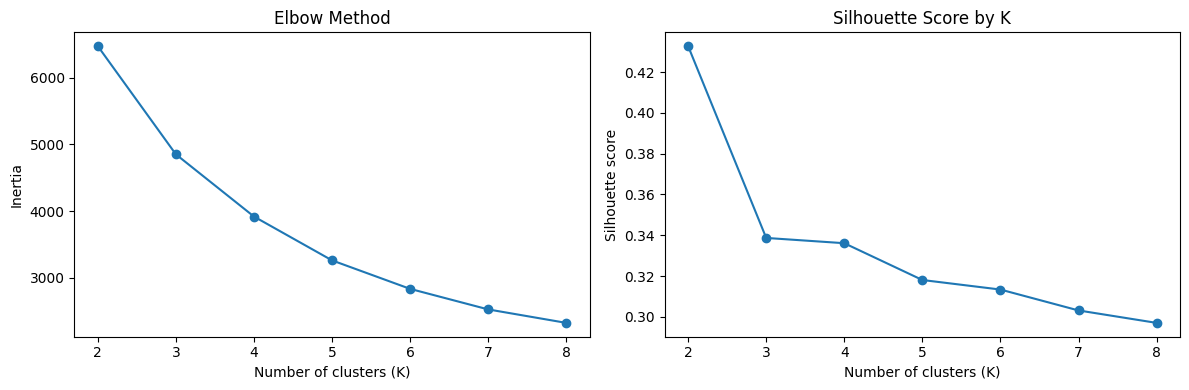

K selected by highest silhouette score: 2


In [10]:
inertia = []
silhouette_values = []
k_values = range(2, min(9, len(rfm)))

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertia.append(model.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, labels))

selection = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia,
    "Silhouette": silhouette_values
})
display(selection)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(selection["K"], selection["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(selection["K"], selection["Silhouette"], marker="o")
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

best_k = int(selection.loc[selection["Silhouette"].idxmax(), "K"])
print("K selected by highest silhouette score:", best_k)

## 6. Fit K-Means and profile clusters

In [11]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
).round(2)

display(profile)
print("K-Means silhouette score:", round(silhouette_score(X_scaled, rfm["KMeans_Cluster"]), 3))

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary
KMeans_Cluster,,,,,,,
0,2672,134.84,1.66,492.82,97.0,1.0,356.92
1,1662,26.33,8.40,4464.75,17.0,6.0,2041.33


K-Means silhouette score: 0.433


## 7. Run DBSCAN

DBSCAN is sensitive to `eps` and the feature scale. The small search below selects a valid candidate with a silhouette score while excluding noise points. If no valid candidate is found, the fallback still produces DBSCAN labels.

In [12]:
dbscan_rows = []
best_dbscan = None
best_dbscan_score = -1

for eps in [0.3, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5]:
    model = DBSCAN(eps=eps, min_samples=10)
    labels = model.fit_predict(X_scaled)
    non_noise = labels != -1
    clusters = set(labels[non_noise])

    score = np.nan
    if non_noise.sum() > 1 and len(clusters) >= 2 and non_noise.sum() > len(clusters):
        try:
            score = silhouette_score(X_scaled[non_noise], labels[non_noise])
        except ValueError:
            pass

    dbscan_rows.append({
        "eps": eps,
        "clusters_excluding_noise": len(clusters),
        "noise_points": int((labels == -1).sum()),
        "noise_ratio": round(float((labels == -1).mean()), 4),
        "silhouette_excluding_noise": score
    })

    if pd.notna(score) and score > best_dbscan_score:
        best_dbscan_score = score
        best_dbscan = model

dbscan_search = pd.DataFrame(dbscan_rows)
display(dbscan_search)

if best_dbscan is None:
    # Safe fallback: labels may all be noise or form fewer than two clusters.
    best_dbscan = DBSCAN(eps=0.7, min_samples=10)
    rfm["DBSCAN_Cluster"] = best_dbscan.fit_predict(X_scaled)
    print("No valid silhouette candidate found. Used fallback eps=0.7.")
else:
    rfm["DBSCAN_Cluster"] = best_dbscan.fit_predict(X_scaled)
    print("Selected DBSCAN eps:", best_dbscan.eps)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

,eps,clusters_excluding_noise,noise_points,noise_ratio,silhouette_excluding_noise
0,0.3,4,414,0.0955,0.146129
1,0.5,2,75,0.0173,0.296547
2,0.7,1,42,0.0097,NaN
3,0.9,1,16,0.0037,NaN
4,1.1,1,10,0.0023,NaN
5,1.3,1,5,0.0012,NaN
6,1.5,1,2,0.0005,NaN


Selected DBSCAN eps: 0.5
DBSCAN_Cluster
-1      75
 0    2767
 1    1492
Name: count, dtype: int64


## 8. PCA projection and visualization

PCA variance explained by 2 components: 0.9386


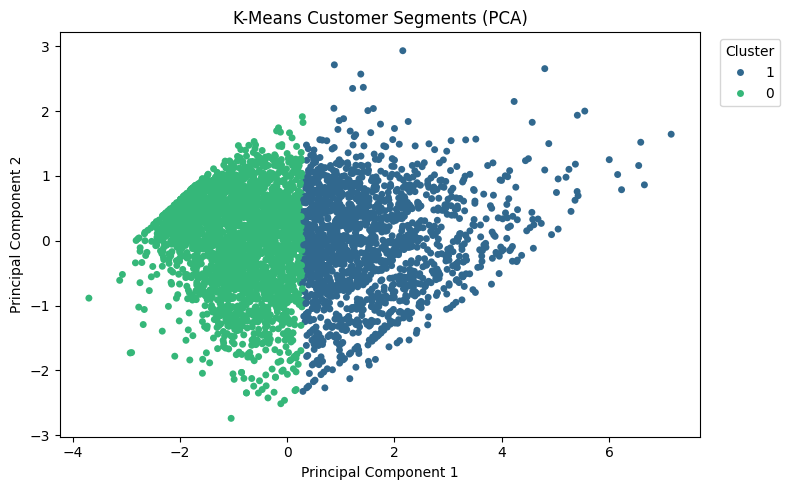

In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print("PCA variance explained by 2 components:",
      round(float(pca.explained_variance_ratio_.sum()), 4))

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=rfm["KMeans_Cluster"].astype(str),
    palette="viridis", s=25, linewidth=0
)
plt.title("K-Means Customer Segments (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 9. t-SNE visualization

For large datasets, t-SNE can take time. It is used here for visualization, not as the input to clustering.

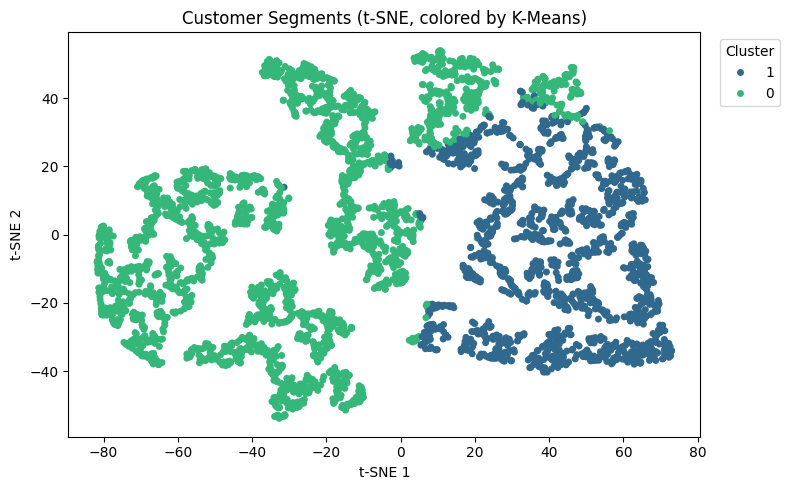

In [14]:
perplexity = min(30, max(2, (len(rfm) - 1) // 3))
tsne = TSNE(
    n_components=2,
    random_state=RANDOM_STATE,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto"
)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=rfm["KMeans_Cluster"].astype(str),
    palette="viridis", s=25, linewidth=0
)
plt.title("Customer Segments (t-SNE, colored by K-Means)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 10. Create customer personas and marketing actions

Personas are assigned to each K-Means cluster using its median RFM profile. Review the actual profiles before presenting them as business findings.

In [15]:
overall_medians = rfm[["Recency", "Frequency", "Monetary"]].median()

def describe_cluster(row):
    tags = []
    if row["Recency"] <= overall_medians["Recency"]:
        tags.append("Recent")
    else:
        tags.append("Needs re-engagement")

    if row["Frequency"] >= overall_medians["Frequency"]:
        tags.append("Frequent")
    else:
        tags.append("Occasional")

    if row["Monetary"] >= overall_medians["Monetary"]:
        tags.append("High spend")
    else:
        tags.append("Lower spend")

    return " / ".join(tags)

cluster_medians = rfm.groupby("KMeans_Cluster")[["Recency", "Frequency", "Monetary"]].median()
cluster_medians["Persona"] = cluster_medians.apply(describe_cluster, axis=1)

def marketing_action(persona):
    actions = []
    if "Recent" in persona and "Frequent" in persona and "High spend" in persona:
        return "VIP rewards, early access, referral offers"
    if "Needs re-engagement" in persona:
        return "Win-back email, personalized recommendations, limited-time offer"
    if "Occasional" in persona:
        return "Second-purchase incentive, welcome journey, product recommendations"
    if "High spend" in persona:
        return "Premium bundles, loyalty rewards, cross-sell complementary products"
    return "Loyalty points, relevant product bundles, tailored recommendations"

cluster_medians["Marketing_Action"] = cluster_medians["Persona"].apply(marketing_action)
display(cluster_medians)

persona_map = cluster_medians["Persona"].to_dict()
action_map = cluster_medians["Marketing_Action"].to_dict()
rfm["Persona"] = rfm["KMeans_Cluster"].map(persona_map)
rfm["Marketing_Action"] = rfm["KMeans_Cluster"].map(action_map)

display(rfm.head(10))

,Recency,Frequency,Monetary,Persona,Marketing_Action
KMeans_Cluster,,,,,
0,97.0,1.0,356.915,Needs re-engagement / Occasional / Lower spend,"Win-back email, personalized recommendations, ..."
1,17.0,6.0,2041.330,Recent / Frequent / High spend,"VIP rewards, early access, referral offers"


,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster,Persona,Marketing_Action
CustomerID,,,,,,,
12346,326,1,77183.60,1,-1,Recent / Frequent / High spend,"VIP rewards, early access, referral offers"
12347,3,7,4310.00,1,0,Recent / Frequent / High spend,"VIP rewards, early access, referral offers"
12348,76,4,1437.24,1,0,Recent / Frequent / High spend,"VIP rewards, early access, referral offers"
12349,19,1,1457.55,0,1,Needs re-engagement / Occasional / Lower spend,"Win-back email, personalized recommendations, ..."
12350,311,1,294.40,0,1,Needs re-engagement / Occasional / Lower spend,"Win-back email, personalized recommendations, ..."
12352,37,7,1385.74,1,0,Recent / Frequent / High spend,"VIP rewards, early access, referral offers"
12353,205,1,89.00,0,1,Needs re-engagement / Occasional / Lower spend,"Win-back email, personalized recommendations, ..."
12354,233,1,1079.40,0,1,Needs re-engagement / Occasional / Lower spend,"Win-back email, personalized recommendations, ..."
12355,215,1,459.40,0,1,Needs re-engagement / Occasional / Lower spend,"Win-back email, personalized recommendations, ..."


## 11. Evaluate clustering and export results

In [17]:
kmeans_score = silhouette_score(X_scaled, rfm["KMeans_Cluster"])
non_noise = rfm["DBSCAN_Cluster"] != -1
dbscan_labels = rfm.loc[non_noise, "DBSCAN_Cluster"]

if non_noise.sum() > 1 and dbscan_labels.nunique() >= 2 and non_noise.sum() > dbscan_labels.nunique():
    try:
        dbscan_score = silhouette_score(X_scaled[non_noise.to_numpy()], dbscan_labels)
    except ValueError:
        dbscan_score = np.nan
else:
    dbscan_score = np.nan

print("K-Means silhouette score:", round(float(kmeans_score), 3))
print("DBSCAN silhouette score (excluding noise):",
      round(float(dbscan_score), 3) if pd.notna(dbscan_score) else "Not defined for these labels")

os.makedirs("outputs", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

rfm.to_csv("outputs/customer_segmentation_results.csv", index=True, index_label="CustomerID")
profile.to_csv("outputs/kmeans_cluster_profile.csv")
cluster_medians.to_csv("outputs/customer_personas.csv")
selection.to_csv("outputs/kmeans_model_selection.csv", index=False)
dbscan_search.to_csv("outputs/dbscan_parameter_search.csv", index=False)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=rfm.index)
pca_df["KMeans_Cluster"] = rfm["KMeans_Cluster"]
pca_df.to_csv("outputs/pca_coordinates.csv", index_label="CustomerID")

tsne_df = pd.DataFrame(X_tsne, columns=["TSNE1", "TSNE2"], index=rfm.index)
tsne_df["KMeans_Cluster"] = rfm["KMeans_Cluster"]
tsne_df.to_csv("outputs/tsne_coordinates.csv", index_label="CustomerID")

print("Results saved in the outputs/ folder.")

K-Means silhouette score: 0.433
DBSCAN silhouette score (excluding noise): 0.297
Results saved in the outputs/ folder.
